# Notebook 02 — Síntesis simbólica, componentes y amplificador operacional
**TP Integrador — Filtros analógicos activos · Grupo 3 · Filtro implementado: LP Chebyshev I, orden 3**

Se trabaja **únicamente con el filtro aprobado**. Contenido:
1. Función de la plantilla $H_t(s)$ (notebook 01) y **función de diseño con margen** $H_d(s)$: estudio de rendimiento frente a tolerancias.
2. Topología: polo real RC + seguidor (U1) y Sallen–Key pasabajos de ganancia unitaria (U2). Esquema con nodos numerados.
3. Análisis nodal simbólico con SymPy (AO ideal): $H_c(s)$, identificación de $\omega_r$, $\omega_0$, $Q$ y ganancia; comparación con Daryanani (8.4)–(8.8).
4. Demostración del aislamiento: transferencia **sin** seguidor y error que introduce la carga.
5. Elección del diseño Sallen–Key (diseños 1, 2 y Saraga de la cátedra) con sensibilidades, dispersión de componentes y efecto del GBW finito.
6. Síntesis: valores normalizados, escaleo, valores comerciales con los capacitores **disponibles en el laboratorio** y resistencias E24 al 1 %
   (con pares en serie), recálculo de $f_0$, $Q$, plantilla y rendimiento esperado.
7. Amplificador operacional (TL072CP, Texas Instruments): hoja técnica, GBW finito, slew rate, modo común, excursión, carga y amplitud máxima.
8. Lista de materiales y exportación para LTspice / notebook 03 / informe.

In [1]:
import sys, json, itertools
from pathlib import Path
import numpy as np
import sympy as sp
import scipy
from scipy import signal
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

print(f"Python {sys.version.split()[0]} | NumPy {np.__version__} | SciPy {scipy.__version__} | SymPy {sp.__version__} | "
      f"Matplotlib {matplotlib.__version__} | pandas {pd.__version__}")

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
FIG, RES = ROOT / 'figuras', ROOT / 'resultados'
FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)

AZUL, NARANJA, VERDE, AMARILLO, GRIS = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#9a9a96'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 300, 'font.size': 9, 'font.family': 'serif', 'mathtext.fontset': 'cm',
    'axes.grid': True, 'grid.color': '#d9d9d6', 'grid.linewidth': 0.6, 'axes.edgecolor': '#6b6b67',
    'axes.linewidth': 0.8, 'lines.linewidth': 1.6, 'legend.frameon': False,
    'axes.spines.top': False, 'axes.spines.right': False,
})
def guardar(fig, nombre):
    fig.savefig(FIG / f'{nombre}.pdf', bbox_inches='tight'); fig.savefig(FIG / f'{nombre}.png', bbox_inches='tight')

def num(x, nd=2):
    """Formato LaTeX con coma decimal y signo menos tipográfico."""
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return '---'
    x = 0.0 if abs(x) < 0.5 * 10**(-nd) else x
    t = f'{abs(x):.{nd}f}'.replace('.', '{,}')
    return ('$-$' + t) if x < 0 else t

def ing(x, unidad=''):
    """Notación de ingeniería legible: 47000 -> '47 k'."""
    for pref, f in [('M', 1e6), ('k', 1e3), ('', 1), ('m', 1e-3), ('µ', 1e-6), ('n', 1e-9), ('p', 1e-12)]:
        if abs(x) >= f * 0.9999:
            return f'{x / f:.4g} {pref}{unidad}'.strip().replace('.', ',')
    return f'{x:.3g} {unidad}'

Python 3.13.18 | NumPy 2.5.3 | SciPy 1.18.1 | SymPy 1.14.0 | Matplotlib 3.11.2 | pandas 3.0.5


## 1. Función de la plantilla y función de diseño con margen
### 1.1 Función de la plantilla $H_t(s)$
Se recalcula con los mismos parámetros del notebook 01: Chebyshev I de orden 3, $A_p = 1$ dB, $f_p = 1$ kHz. Tiene **exactamente** 1 dB de rizado,
es decir, margen nulo en la banda de paso.

In [2]:
AP, AS = 1.0, 24.0
FP_SPEC, FS_SPEC = 1000.0, 4000.0
N, wn = signal.cheb1ord(2 * np.pi * FP_SPEC, 2 * np.pi * FS_SPEC, AP, AS, analog=True)

def cheby3(Ap_dB, fp_Hz):
    """Chebyshev I de orden N: devuelve (z, p, k), w_r, w_0, Q."""
    z, p, k = signal.cheby1(N, Ap_dB, 2 * np.pi * fp_Hz, 'lowpass', analog=True, output='zpk')
    pr = p[np.abs(p.imag) < 1e-6 * np.abs(p)].real[0]
    pc = p[p.imag > 0][0]
    return (z, p, k), -pr, abs(pc), abs(pc) / (-2 * pc.real)

ZPK_T, WR_SPEC, W0_SPEC, Q_SPEC = cheby3(AP, FP_SPEC)
print(f'H_t: N = {N}, f_r = {WR_SPEC/2/np.pi:.4f} Hz | f_0 = {W0_SPEC/2/np.pi:.4f} Hz | Q = {Q_SPEC:.5f}')

def resp(zpk, f):
    _, H = signal.freqs_zpk(*zpk, worN=2 * np.pi * np.asarray(f, float))
    return H
Ht = lambda f: resp(ZPK_T, f)

H_t: N = 3, f_r = 494.1706 Hz | f_0 = 997.0981 Hz | Q = 2.01772


### 1.2 Rendimiento frente a tolerancias y margen de diseño
Un circuito construido no realiza $H_t$ sino una función con $f_r$, $f_0$ y $Q$ desplazados por las tolerancias. Como $H_t$ no tiene margen en la banda
de paso, se estima el **rendimiento** (porcentaje de circuitos que cumplen la plantilla) mediante un Monte Carlo analítico rápido sobre el circuito
elegido (RC + Sallen–Key $k=1$, §3), con distribuciones uniformes e independientes: $R$ ±1 %, $C$ ±5 % o ±10 %. Se comparan funciones de diseño
Chebyshev I de orden 3 con rizado $A_{p,d} \le A_p$ y borde $f_{p,d} \ge f_p$: ambas son **más exigentes** que la plantilla, de modo que el diseño
nominal sigue cumpliendo y la diferencia queda disponible para absorber tolerancias. El precio es una menor atenuación a 4 kHz, que tiene ~18 dB de
margen en $H_t$. (Este estudio es una estimación de diseño; el análisis estadístico con LTspice corresponde al Nivel II.)

In [3]:
RNG = np.random.default_rng(2026)
F_MC = np.concatenate([np.geomspace(1, FP_SPEC, 400), [FP_SPEC]])

def componentes_ideales(wr, w0, Q, n=None):
    """Valores normalizados (C0 = C2 = 1): solo importan los cocientes. Si no se indica n, se usa un par de capacitores
    disponible: C1/C2 = 47n/4,7n = 10 si alcanza (n >= 4Q^2) o 100n/4,7n = 21,3 si no."""
    if n is None:
        n = 10.0 if 4 * Q**2 <= 10.0 else 100 / 4.7
    q = np.sqrt(1 - 4 * Q**2 / n)
    return dict(R0=1 / wr, C0=1.0, R1=(1 + q) / (2 * Q * w0), R2=(1 - q) / (2 * Q * w0), C1=n, C2=1.0)

def monte_carlo(comp, tolR, tolC, M=20000, rng=RNG):
    """comp: dict con R0, C0, R1, R2, C1, C2 (R0 incluye Rs). Cada R puede ser lista (resistencias en serie, cada una con su tolerancia)."""
    u = lambda t: 1 + t * rng.uniform(-1, 1, M)
    def R(x):
        return sum(v * u(tolR) for v in (x if isinstance(x, (list, tuple)) else [x]))
    r0, r1, r2 = R(comp['R0']), R(comp['R1']), R(comp['R2'])
    c0, c1, c2 = comp['C0'] * u(tolC), comp['C1'] * u(tolC), comp['C2'] * u(tolC)
    r0 = r0 + comp.get('Rs', 0.0)
    a, b, c = 1 / (r0 * c0), 1 / (r1 * r2 * c1 * c2), (r1 + r2) / (r1 * r2 * c1)
    H = lambda sj: (a / (sj + a)) * (b / (sj**2 + c * sj + b))
    Hp = H(2j * np.pi * F_MC[:, None]); mx = np.maximum(np.abs(Hp).max(0), 1.0)
    Apm = (-20 * np.log10(np.abs(Hp) / mx)).max(0)
    A4 = -20 * np.log10(np.abs(H(2j * np.pi * FS_SPEC)) / mx)
    return Apm, A4

filas = []
OPCIONES = [(1.0, 1000), (0.5, 1000), (0.5, 1050), (0.4, 1060), (0.3, 1060), (0.25, 1080), (0.2, 1100)]
for Apd, fpd in OPCIONES:
    _, wr_, w0_, Q_ = cheby3(Apd, fpd)
    comp_ = componentes_ideales(wr_, w0_, Q_)
    fila = {'A_p,d [dB]': Apd, 'f_p,d [Hz]': fpd, 'Q': Q_}
    for tolC in (0.05, 0.10):
        Apm, A4 = monte_carlo(comp_, 0.01, tolC)
        fila[f'rend. C±{tolC*100:.0f}% [%]'] = 100 * np.mean((Apm <= AP) & (A4 >= AS))
        fila[f'A_p p95 C±{tolC*100:.0f}% [dB]'] = np.percentile(Apm, 95)
    fila['A(4 kHz) nominal [dB]'] = -20 * np.log10(abs(resp(cheby3(Apd, fpd)[0], [FS_SPEC])[0]))
    filas.append(fila)
margen = pd.DataFrame(filas)
margen.round(3)

,"A_p,d [dB]","f_p,d [Hz]",Q,rend. C±5% [%],A_p p95 C±5% [dB],rend. C±10% [%],A_p p95 C±10% [dB],A(4 kHz) nominal [dB]
0,1.00,1000,2.018,4.115,1.665,4.155,2.398,41.880
1,0.50,1000,1.706,97.565,0.945,66.535,1.448,38.613
2,0.50,1050,1.706,100.000,0.762,88.300,1.108,37.298
3,0.40,1060,1.633,100.000,0.654,95.160,0.997,36.022
4,0.30,1060,1.552,100.000,0.549,98.260,0.898,34.722
5,0.25,1080,1.508,100.000,0.489,99.520,0.826,33.400
6,0.20,1100,1.460,100.000,0.432,99.970,0.763,31.910


**Decisión (acordada con el grupo): función de diseño $H_d$ = Chebyshev I de orden 3 con $A_{p,d} = 0{,}3$ dB y $f_{p,d} = 1060$ Hz.**
Sigue siendo el filtro aprobado (Chebyshev I, orden 3) pero con presupuesto de error: el rendimiento estimado sube del ~4 % (diseño sin margen) a
~100 % con capacitores de ±5 % y ~98 % con ±10 %, conservando ~11 dB de margen nominal a 4 kHz. Toda la síntesis que sigue usa $H_d$; la
verificación final se hace **siempre contra la plantilla** ($A_p = 1$ dB, $f_p = 1$ kHz, $A_s = 24$ dB, $f_s = 4$ kHz).

H_d: f_r = 773.0340 Hz (w_r = 4857.116 rad/s) | f_0 = 1200.1173 Hz (w_0 = 7540.559 rad/s) | Q = 1.55248 | 4Q^2 = 9.641


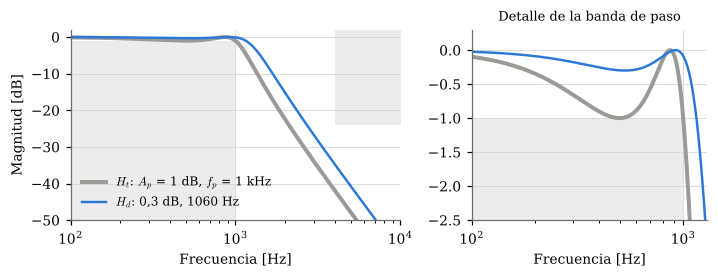

In [4]:
AP_D, FP_D = 0.3, 1060.0
ZPK_D, WR_T, W0_T, Q_T = cheby3(AP_D, FP_D)
FR_T, F0_T = WR_T / (2 * np.pi), W0_T / (2 * np.pi)
Hd = lambda f: resp(ZPK_D, f)
zt, pt, kt = ZPK_D
print(f'H_d: f_r = {FR_T:.4f} Hz (w_r = {WR_T:.3f} rad/s) | f_0 = {F0_T:.4f} Hz (w_0 = {W0_T:.3f} rad/s) | Q = {Q_T:.5f} | 4Q^2 = {4*Q_T**2:.3f}')

fm = np.geomspace(100, 1e4, 3000)
fig, axs = plt.subplots(1, 2, figsize=(6.6, 2.6), gridspec_kw={'width_ratios': [1.4, 1]})
for ax, lims in [(axs[0], dict(xlim=(100, 1e4), ylim=(-50, 2))), (axs[1], dict(xlim=(100, 1300), ylim=(-2.5, 0.3)))]:
    ax.semilogx(fm, 20 * np.log10(np.abs(Ht(fm))), color=GRIS, lw=2.6, label='$H_t$: $A_p$ = 1 dB, $f_p$ = 1 kHz')
    ax.semilogx(fm, 20 * np.log10(np.abs(Hd(fm))), color=AZUL, label='$H_d$: 0,3 dB, 1060 Hz')
    ax.fill_between([1, FP_SPEC], -90, -AP, color=GRIS, alpha=0.18, lw=0)
    ax.fill_between([FS_SPEC, 1e6], -AS, 5, color=GRIS, alpha=0.18, lw=0)
    ax.set(xlabel='Frecuencia [Hz]', **lims)
axs[0].set_ylabel('Magnitud [dB]'); axs[0].legend(fontsize=8, loc='lower left')
axs[1].set_title('Detalle de la banda de paso', fontsize=8.5)
fig.tight_layout(); guardar(fig, 'fig_Ht_vs_Hd'); plt.show()

## 2. Topología y esquema
- **Etapa 1 (polo real):** red $R_0C_0$ seguida de un seguidor de tensión (U1). La resistencia interna del generador $R_s$ queda en serie con $R_0$ y se
  incluye en el modelo. El seguidor aísla la red RC de la carga de la etapa 2 y entrega a ésta una fuente de impedancia prácticamente nula.
- **Etapa 2 (par complejo):** Sallen–Key pasabajos (Daryanani, fig. 8.3) con **ganancia unitaria** ($k=1$: $r_2 = 0$, $r_1 \to \infty$), es decir U2 como seguidor.
- **Orden de la cascada:** primero la sección de 1.er orden (notebook 01, §6): ningún nodo intermedio supera la ganancia de salida en la banda de paso.

Numeración de nodos (la misma se usa en el netlist de LTspice): 0 masa, 1 salida del generador, 2 nodo $R_0C_0$ (entrada no inversora de U1),
3 salida de U1, 4 nodo central del Sallen–Key, 5 entrada no inversora de U2, 6 salida $v_o$.

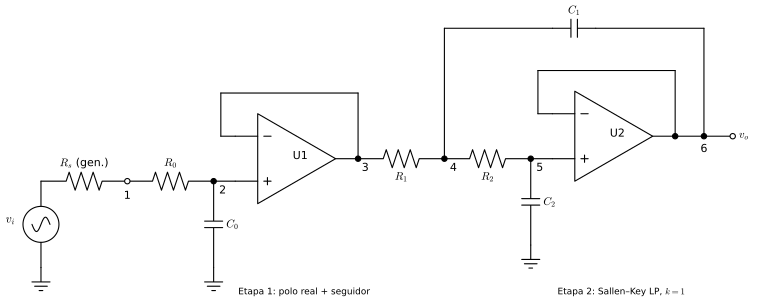

In [5]:
try:
    import schemdraw
    import schemdraw.elements as elm
except ImportError:                                     # en Colab: !pip install schemdraw
    import subprocess
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'schemdraw'], check=True)
    import schemdraw
    import schemdraw.elements as elm

def dibujar_esquema(destinos):
    schemdraw.config(fontsize=11, lw=1.1)
    with schemdraw.Drawing(show=False) as d:
        d.config(unit=2.4)
        src = d.add(elm.SourceSin().up())
        d.add(elm.Label().at((src.center[0] - 0.75, src.center[1])).label('$v_i$', fontsize=12))
        d.add(elm.Ground().at(src.start))
        d.add(elm.Resistor().right().at(src.end).label('$R_s$ (gen.)', loc='top'))
        d.add(elm.Dot(open=True).label('1', loc='bottom', ofst=0.15))
        d.add(elm.Resistor().right().label('$R_0$', loc='top'))
        d.add(elm.Dot().label('2', loc='bottom', ofst=(0.25, 0)))
        d.push(); d.add(elm.Capacitor().down().label('$C_0$', loc='bottom')); d.add(elm.Ground()); d.pop()
        d.add(elm.Line().right(0.6))
        u1 = d.add(elm.Opamp(leads=True).right().anchor('in2').label('U1', loc='center'))
        d.add(elm.Line().at(u1.in1).left(0.4)); d.add(elm.Line().up(1.2))
        d.add(elm.Line().tox(u1.out)); d.add(elm.Line().toy(u1.out))
        d.add(elm.Dot().at(u1.out).label('3', loc='bottom', ofst=(0.2, 0)))
        d.add(elm.Resistor().right().at(u1.out).label('$R_1$', loc='bottom'))
        n4 = d.add(elm.Dot().label('4', loc='bottom', ofst=(0.25, 0)))
        d.add(elm.Resistor().right().label('$R_2$', loc='bottom'))
        d.add(elm.Dot().label('5', loc='bottom', ofst=(0.25, 0)))
        d.push(); d.add(elm.Capacitor().down().label('$C_2$', loc='bottom')); d.add(elm.Ground()); d.pop()
        d.add(elm.Line().right(0.6))
        u2 = d.add(elm.Opamp(leads=True).right().anchor('in2').label('U2', loc='center'))
        d.add(elm.Line().at(u2.in1).left(0.4)); d.add(elm.Line().up(1.2))
        d.add(elm.Line().tox(u2.out)); d.add(elm.Line().toy(u2.out))
        d.add(elm.Dot().at(u2.out))
        d.add(elm.Line().right(0.8).at(u2.out))
        n6 = d.add(elm.Dot().label('6', loc='bottom', ofst=(0, -0.1)))
        d.add(elm.Line().right(0.8))
        d.add(elm.Dot(open=True).label('$v_o$', loc='right'))
        ytop = u2.out[1] + 3.0
        d.add(elm.Line().at(n4.center).toy(ytop))
        xm = (n4.center[0] + n6.center[0]) / 2
        d.add(elm.Line().tox(xm - 0.6))
        d.add(elm.Capacitor().right(1.2).label('$C_1$', loc='top'))
        d.add(elm.Line().tox(n6.center)); d.add(elm.Line().toy(n6.center))
        y_et = min(u1.out[1], u2.out[1]) - 3.6
        d.add(elm.Label().at((u1.out[0] - 1.6, y_et)).label('Etapa 1: polo real + seguidor', fontsize=9))
        d.add(elm.Label().at((u2.out[0] - 1.6, y_et)).label('Etapa 2: Sallen–Key LP, $k = 1$', fontsize=9))
        for destino in destinos:
            d.save(str(destino))
    return d

esq = dibujar_esquema([FIG / 'fig_esquema.pdf', FIG / 'fig_esquema.png', FIG / 'fig_esquema.svg'])
esq

## 3. Análisis nodal simbólico (AO ideal)
Ecuaciones (KCL en los nodos 1, 2, 4 y 5; AO ideal: realimentación negativa $\Rightarrow v^+ = v^-$, corriente de entrada nula):
$$\begin{aligned}
\text{nodo 1:}&\quad \frac{V_i-V_1}{R_s} = \frac{V_1-V_2}{R_0} &\qquad
\text{nodo 2:}&\quad \frac{V_1-V_2}{R_0} = sC_0V_2 \\
\text{U1:}&\quad V_3 = V_2 &
\text{nodo 4:}&\quad \frac{V_3-V_4}{R_1} + (V_6-V_4)\,sC_1 + \frac{V_5-V_4}{R_2} = 0 \\
\text{nodo 5:}&\quad \frac{V_4-V_5}{R_2} = sC_2V_5 &
\text{U2:}&\quad V_6 = V_5
\end{aligned}$$

In [6]:
s = sp.symbols('s')
Rs, R0, C0, R1, R2, C1, C2 = sp.symbols('R_s R_0 C_0 R_1 R_2 C_1 C_2', positive=True)
Vi = sp.symbols('V_i')
V = sp.symbols('V1:7')                     # V1..V6
V1, V2, V3, V4, V5, V6 = V

def ecuaciones(buffer=True, A=None):
    """KCL del circuito. buffer=False elimina U1 (la red RC alimenta directamente al Sallen-Key).
    A: ganancia de lazo abierto de los AO (None = ideal)."""
    eqs = [sp.Eq((Vi - V1) / Rs, (V1 - V2) / R0)]
    if buffer:
        eqs.append(sp.Eq((V1 - V2) / R0, s * C0 * V2))
        eqs.append(sp.Eq(V3, V2) if A is None else sp.Eq(V3, A * (V2 - V3)))
    else:
        eqs.append(sp.Eq((V1 - V2) / R0, s * C0 * V2 + (V2 - V4) / R1))
        eqs.append(sp.Eq(V3, V2))
    eqs.append(sp.Eq((V3 - V4) / R1 + (V6 - V4) * s * C1 + (V5 - V4) / R2, 0))
    eqs.append(sp.Eq((V4 - V5) / R2, s * C2 * V5))
    eqs.append(sp.Eq(V6, V5) if A is None else sp.Eq(V6, A * (V5 - V6)))
    return eqs

sol = sp.solve(ecuaciones(), V, dict=True)[0]
Hc = sp.factor(sp.simplify(sol[V6] / Vi))
display(sp.Eq(sp.Symbol('H_c(s)'), Hc))

Eq(H_c(s), 1/((C_0*R_0*s + C_0*R_s*s + 1)*(C_1*C_2*R_1*R_2*s**2 + C_2*R_1*s + C_2*R_2*s + 1)))

**Identificación de parámetros.** Se separa $H_c$ en el factor de primer orden (que depende solo de $R_s+R_0$ y $C_0$) y el bicuadrático, y se
leen $\omega_r$, $\omega_0$, $Q$ y la ganancia en continua igualando coeficientes con las formas canónicas.

In [7]:
T1c = sp.simplify(sol[V2] / Vi)                     # = sol[V3]/Vi: salida de la etapa 1
T2c = sp.factor(sp.simplify(sol[V6] / sol[V3]))     # etapa 2 aislada
display(sp.Eq(sp.Symbol('T_1(s)'), T1c), sp.Eq(sp.Symbol('T_2(s)'), T2c))
print('¿H_c = T1·T2?', sp.simplify(Hc - T1c * T2c) == 0)

def parametros_bicuad(T):
    n_, d_ = sp.fraction(sp.together(T))
    c = sp.Poly(sp.expand(d_), s).all_coeffs()
    a2, a1, a0 = [sp.simplify(x / c[0]) for x in c]
    w0 = sp.sqrt(a0)
    return sp.simplify(w0), sp.simplify(w0 / a1), sp.simplify((sp.Poly(sp.expand(n_), s).all_coeffs()[-1] / c[0]) / a0)

wr_c = sp.simplify(1 / ((Rs + R0) * C0))
w0_c, Q_c, K_c = parametros_bicuad(T2c)
display(sp.Eq(sp.Symbol(r'\omega_r'), wr_c), sp.Eq(sp.Symbol(r'\omega_0'), w0_c),
        sp.Eq(sp.Symbol('Q'), Q_c), sp.Eq(sp.Symbol('H_2(0)'), K_c))
print('Comprobación T1 = w_r/(s+w_r):', sp.simplify(T1c - wr_c / (s + wr_c)) == 0)

Eq(T_1(s), 1/(C_0*R_0*s + C_0*R_s*s + 1))

Eq(T_2(s), 1/(C_1*C_2*R_1*R_2*s**2 + C_2*R_1*s + C_2*R_2*s + 1))

¿H_c = T1·T2? True


Eq(\omega_r, 1/(C_0*(R_0 + R_s)))

Eq(\omega_0, 1/(sqrt(C_1)*sqrt(C_2)*sqrt(R_1)*sqrt(R_2)))

Eq(Q, sqrt(C_1)*sqrt(R_1)*sqrt(R_2)/(sqrt(C_2)*(R_1 + R_2)))

Eq(H_2(0), 1)

Comprobación T1 = w_r/(s+w_r): True


**Contraste con Daryanani (8.4)–(8.8)** para el Sallen–Key general de ganancia $k = 1 + r_2/r_1$:
$\omega_p = 1/\sqrt{R_1R_2C_1C_2}$, $\;(\mathrm{bw})_p = \dfrac{1}{R_1C_1}+\dfrac{1}{R_2C_1}+\dfrac{1-k}{R_2C_2}$, $\;Q_p = \omega_p/(\mathrm{bw})_p$.
Se deriva el caso general con SymPy y se verifica que con $k=1$ coincide con lo obtenido arriba.

In [8]:
r1, r2, k = sp.symbols('r_1 r_2 k', positive=True)
Vx, Vp, Vo_, Vin2 = sp.symbols('V_x V_p V_o V_in2')
eq_sk = [sp.Eq((Vin2 - Vx) / R1 + (Vo_ - Vx) * s * C1 + (Vp - Vx) / R2, 0),
         sp.Eq((Vx - Vp) / R2, s * C2 * Vp),
         sp.Eq(Vo_, (1 + r2 / r1) * Vp)]
sk = sp.solve(eq_sk, [Vx, Vp, Vo_], dict=True)[0]
T_sk = sp.factor(sp.simplify(sk[Vo_] / Vin2))
w0_g, Q_g, K_g = parametros_bicuad(T_sk)
kk = 1 + r2 / r1
w0_dar = 1 / sp.sqrt(R1 * R2 * C1 * C2)
bw_dar = 1 / (R1 * C1) + 1 / (R2 * C1) + (1 - kk) / (R2 * C2)
print('w0 general = Daryanani (8.6):', sp.simplify(w0_g - w0_dar) == 0)
print('Q  general = Daryanani (8.7):', sp.simplify(Q_g - w0_dar / bw_dar) == 0)
print('K  general = k (8.8):        ', sp.simplify(K_g - kk) == 0)
print('Caso k=1 (r2 -> 0) = circuito implementado:', sp.simplify(Q_g.subs(r2, 0) - Q_c) == 0)
display(sp.Eq(sp.Symbol('Q_{k=1}'), sp.simplify(Q_g.subs(r2, 0))))

w0 general = Daryanani (8.6): True
Q  general = Daryanani (8.7): True
K  general = k (8.8):         True
Caso k=1 (r2 -> 0) = circuito implementado: True


Eq(Q_{k=1}, sqrt(C_1)*sqrt(R_1)*sqrt(R_2)/(sqrt(C_2)*(R_1 + R_2)))

## 4. Aislamiento entre etapas
Sin U1, la red $R_0C_0$ queda cargada por la impedancia de entrada del Sallen–Key, que depende de la frecuencia: el denominador deja de factorizarse
como $(s+\omega_r)(s^2+\frac{\omega_0}{Q}s+\omega_0^2)$ y los polos se desplazan. Se cuantifica con los valores comerciales elegidos más abajo
(§6); aquí se muestra la estructura.

In [9]:
sol_nb = sp.solve(ecuaciones(buffer=False), V, dict=True)[0]
H_nb = sp.factor(sp.simplify(sol_nb[V6] / Vi))
n_nb, d_nb = sp.fraction(H_nb)
n_c, d_c = sp.fraction(Hc)
dif = sp.factor(sp.expand(sp.Poly(d_nb, s).monic().as_expr() - sp.Poly(d_c, s).monic().as_expr()))
print('Diferencia de denominadores mónicos (sin buffer − con buffer):')
display(dif)

Diferencia de denominadores mónicos (sin buffer − con buffer):


s*(C_1*R_2*s + 1)/(C_0*C_1*R_1*R_2)

El término de diferencia resulta $\dfrac{s\,(sC_1R_2+1)}{C_0C_1R_1R_2}$: desaparece solo si $R_1 \to \infty$ o $C_0\to\infty$, es decir, si la
etapa 2 no carga a la etapa 1. Con U1 ideal el acoplamiento es nulo **exactamente**, y con un AO real queda acotado por su impedancia de salida en lazo
cerrado (del orden de $r_o/(1+A)$, miliohms a 1 kHz), despreciable frente a $R_1$.

## 5. Elección del diseño Sallen–Key
Antes de imponer igualdades entre componentes se calculan con SymPy las sensibilidades normalizadas $S_x^{Q} = \dfrac{x}{Q}\dfrac{\partial Q}{\partial x}$
del Sallen–Key general (seis elementos: $R_1,R_2,C_1,C_2,r_1,r_2$) y se evalúan en los tres diseños de la cátedra (Daryanani, tabla 8.1) para
$Q = Q_t$. Además se estima el corrimiento de $f_0$ y $Q$ por GBW finito, con $A(s) = \omega_t/s$.

In [10]:
def S(y, x):
    return sp.simplify(x * sp.diff(y, x) / y)

elementos = [R1, R2, C1, C2, r1, r2]
SQ_g = {x: S(Q_g, x) for x in elementos}
Sw0_g = {x: S(w0_g, x) for x in elementos}
for x in elementos:
    display(sp.Eq(sp.Symbol(f'S^Q_{{{sp.latex(x)}}}'), SQ_g[x]))

q = Q_T
DISENOS = {
    'Diseño 1 ($k=1$)':        dict(R1=1, R2=1, C1=2 * q, C2=1 / (2 * q), r1=1, r2=0),
    'Diseño 2 (iguales)':      dict(R1=1, R2=1, C1=1, C2=1, r1=1, r2=2 - 1 / q),
    'Diseño 3 (Saraga)':       dict(R1=1 / q, R2=1 / np.sqrt(3), C1=np.sqrt(3) * q, C2=1, r1=3, r2=1),
}
# AO con ganancia finita A(s) = wt/s en el Sallen-Key general
Aop = sp.Symbol('A')
eq_skA = eq_sk[:2] + [sp.Eq(Vo_, Aop * (Vp - Vo_ * r1 / (r1 + r2)))]
T_skA = sp.simplify(sp.solve(eq_skA, [Vx, Vp, Vo_], dict=True)[0][Vo_] / Vin2)

def efecto_gbw(d, ft, z=1e4):
    """Corrimiento de f0 y Q (en %) del par de polos dominante con A(s)=2*pi*ft/s, escalado a W0_T y nivel z."""
    sub = {R1: d['R1'] * z, R2: d['R2'] * z, C1: d['C1'] / (z * W0_T), C2: d['C2'] / (z * W0_T),
           r1: d['r1'] * z, r2: d['r2'] * z, Aop: 2 * np.pi * ft / s}
    _, den = sp.fraction(sp.together(T_skA.subs(sub)))
    p = np.roots([float(c) for c in sp.Poly(sp.expand(den), s).all_coeffs()])
    pc = p[(p.imag > 0) & (np.abs(p) < 20 * W0_T)][0]
    return 100 * (abs(pc) / W0_T - 1), 100 * ((abs(pc) / (-2 * pc.real)) / Q_T - 1)

filas = []
for nombre, d in DISENOS.items():
    sub = {R1: d['R1'], R2: d['R2'], C1: d['C1'], C2: d['C2'], r1: d['r1'], r2: d['r2']}
    fila = {'Diseño': nombre, 'k': 1 + d['r2'] / d['r1'],
            'C1/C2': d['C1'] / d['C2'], 'Q (verif.)': float(Q_g.subs(sub)), 'w0 (verif.)': float(w0_g.subs(sub))}
    for x in elementos:
        fila[f'S^Q_{x}'] = float(SQ_g[x].subs(sub)) if d['r2'] > 0 or x not in (r1, r2) else 0.0
    fila['max|S^Q|'] = max(abs(fila[f'S^Q_{x}']) for x in elementos)
    fila['sum|S^Q|'] = sum(abs(fila[f'S^Q_{x}']) for x in elementos)
    fila['df0 TL072 [%]'], fila['dQ TL072 [%]'] = efecto_gbw(d, 3e6)
    fila['df0 LM358 [%]'], fila['dQ LM358 [%]'] = efecto_gbw(d, 0.7e6)
    filas.append(fila)
comp_dis = pd.DataFrame(filas).set_index('Diseño')
comp_dis.round(3).T

Eq(S^Q_{R_{1}}, (-C_1*R_1*r_2 + C_2*R_1*r_1 - C_2*R_2*r_1)/(2*(C_1*R_1*r_2 - C_2*R_1*r_1 - C_2*R_2*r_1)))

Eq(S^Q_{R_{2}}, (-C_1*R_1*r_2 + C_2*R_1*r_1 - C_2*R_2*r_1)/(2*(-C_1*R_1*r_2 + C_2*R_1*r_1 + C_2*R_2*r_1)))

Eq(S^Q_{C_{1}}, (C_1*R_1*r_2 + C_2*R_1*r_1 + C_2*R_2*r_1)/(2*(-C_1*R_1*r_2 + C_2*R_1*r_1 + C_2*R_2*r_1)))

Eq(S^Q_{C_{2}}, (C_1*R_1*r_2 + C_2*R_1*r_1 + C_2*R_2*r_1)/(2*(C_1*R_1*r_2 - C_2*R_1*r_1 - C_2*R_2*r_1)))

Eq(S^Q_{r_{1}}, C_1*R_1*r_2/(C_1*R_1*r_2 - C_2*R_1*r_1 - C_2*R_2*r_1))

Eq(S^Q_{r_{2}}, C_1*R_1*r_2/(-C_1*R_1*r_2 + C_2*R_1*r_1 + C_2*R_2*r_1))

Diseño,Diseño 1 ($k=1$),Diseño 2 (iguales),Diseño 3 (Saraga)
k,1.000,2.356,1.333
C1/C2,9.641,1.000,2.689
Q (verif.),1.552,1.552,1.552
w0 (verif.),1.000,1.000,1.000
S^Q_R_1,0.000,1.052,0.396
S^Q_R_2,0.000,-1.052,-0.396
S^Q_C_1,0.500,2.605,1.396
S^Q_C_2,-0.500,-2.605,-1.396
S^Q_r_1,0.000,-2.105,-0.896
S^Q_r_2,0.000,2.105,0.896


**Decisión: diseño 1 (ganancia unitaria), en su forma generalizada.** Tiene las menores sensibilidades pasivas de $Q$ ($0$ respecto de las
resistencias y $\pm\tfrac12$ respecto de los capacitores), no necesita red de ganancia $r_1, r_2$ (menos componentes y $H(0)=1$ sin ajuste de ganancia)
y el AO trabaja como seguidor (máxima realimentación). Su única contra es la dispersión de capacitores $C_1/C_2 \ge 4Q^2$ (≈ 9,6 con $H_d$), que no es
un problema práctico: en lugar de imponer $R_1=R_2$ se eligen **dos capacitores disponibles** con $n = C_1/C_2 \ge 4Q^2$ y se despejan $R_1 \ne R_2$.
El efecto del GBW finito es despreciable en los tres diseños, de modo que no decide la elección.

Con $k = 1$: $\;\omega_0^2 = \dfrac{1}{R_1R_2C_1C_2}$, $\;\dfrac{\omega_0}{Q} = \dfrac{R_1+R_2}{R_1R_2C_1}$. Fijados $C_1 = nC_2$, $R_1$ y $R_2$ son las
raíces de $x^2 - \dfrac{x}{Q\omega_0C_2} + \dfrac{1}{\omega_0^2C_1C_2} = 0$:
$$R_{1,2} = \frac{1\pm\sqrt{1-4Q^2/n}}{2\,Q\,\omega_0\,C_2},\qquad n \ge 4Q^2 .$$

In [11]:
SQ_k1 = {x: sp.simplify(SQ_g[x].subs(r2, 0)) for x in [R1, R2, C1, C2]}
for x, v in SQ_k1.items():
    display(sp.Eq(sp.Symbol(f'S^Q_{{{sp.latex(x)}}}|_{{k=1}}'), v))
Sw0_k1 = {x: sp.simplify(Sw0_g[x].subs(r2, 0)) for x in [R1, R2, C1, C2]}
print('S^w0 (k=1):', Sw0_k1)

Eq(S^Q_{R_{1}}|_{k=1}, (-R_1 + R_2)/(2*(R_1 + R_2)))

Eq(S^Q_{R_{2}}|_{k=1}, (R_1 - R_2)/(2*(R_1 + R_2)))

Eq(S^Q_{C_{1}}|_{k=1}, 1/2)

Eq(S^Q_{C_{2}}|_{k=1}, -1/2)

S^w0 (k=1): {R_1: -1/2, R_2: -1/2, C_1: -1/2, C_2: -1/2}


## 6. Síntesis y valores comerciales
### 6.1 Procedimiento de la cátedra: diseño normalizado y escaleo
Diseño normalizado con $\omega_0 = 1$ rad/s y $C_2 = 1$ F; luego escaleo de frecuencia ($k_f = \omega_0$: $C \to C/k_f$) y de impedancia
($k_z$: $R \to k_zR$, $C \to C/k_z$). El escaleo no altera $Q$ ni la forma de la respuesta.

In [12]:
E24 = [1.0, 1.1, 1.2, 1.3, 1.5, 1.6, 1.8, 2.0, 2.2, 2.4, 2.7, 3.0, 3.3, 3.6, 3.9, 4.3, 4.7, 5.1, 5.6, 6.2, 6.8, 7.5, 8.2, 9.1]
E24_R = sorted(set(round(x * 10**d, 6) for d in range(1, 7) for x in E24))          # 10 Ω ... 9,1 MΩ
# Capacitores disponibles en el laboratorio (se excluyen los pF, demasiado chicos para estos niveles de impedancia,
# y los de 2,2 µF o más, presumiblemente electrolíticos)
CAP_DISP = [1e-9, 4.7e-9, 10e-9, 47e-9, 100e-9, 150e-9, 220e-9, 330e-9, 470e-9, 680e-9, 1e-6]
CAP_LISTA_COMPLETA = '10p, 20p, 30p, 47p, 56p, 68p, 100p, 200p, 300p, 680p, 1n, 4.7n, 10n, 47n, 100n, 150n, 220n, 330n, 470n, 680n, 1µ, 2.2µ, 4.7µ, 10µ'

def R12(n, Q, w0, C2):
    """Resistencias del Sallen-Key k=1 para C1 = n*C2 (raíz mayor, raíz menor)."""
    raiz = np.sqrt(1 - 4 * Q**2 / n)
    return (1 + raiz) / (2 * Q * w0 * C2), (1 - raiz) / (2 * Q * w0 * C2)

PARES = [(a,) for a in E24_R] + [(a, b) for a in E24_R for b in E24_R if a / 100 <= b <= a]
VALS = np.array([sum(p) for p in PARES])
def e24(x):
    s = np.asarray(E24_R); return float(s[np.argmin(np.abs(np.log(s / x)))])
def e24_serie(x, tol_simple=0.0025):
    """Una resistencia E24 si el error es <= tol_simple; si no, el mejor par en serie (cada una del 1 %)."""
    r = e24(x)
    if abs(r / x - 1) <= tol_simple:
        return (r,), r
    i = int(np.argmin(np.abs(np.log(VALS / x))))
    return PARES[i], float(VALS[i])
def txt_serie(p):
    return ' + '.join(ing(v, 'Ω') for v in p)

n_ej = 47 / 4.7
Rn_may, Rn_men = R12(n_ej, Q_T, 1.0, 1.0)
kf = W0_T; kz = 1 / (kf * 4.7e-9)
print(f'Normalizado (w0 = 1, C2 = 1 F, C1 = {n_ej:.3f} F): R = {Rn_may:.5f} Ω y {Rn_men:.5f} Ω')
print(f'k_f = {kf:.2f} rad/s, k_z = {kz:.1f}  ->  C2 = {1/(kf*kz)*1e9:.3f} nF, C1 = {n_ej/(kf*kz)*1e9:.3f} nF, '
      f'R = {Rn_may*kz/1e3:.4f} kΩ y {Rn_men*kz/1e3:.4f} kΩ')

Normalizado (w0 = 1, C2 = 1 F, C1 = 10.000 F): R = 0.38311 Ω y 0.26102 Ω
k_f = 7540.56 rad/s, k_z = 28216.2  ->  C2 = 4.700 nF, C1 = 47.000 nF, R = 10.8099 kΩ y 7.3650 kΩ


### 6.2 Elección de capacitores entre los disponibles
Para cada par disponible con $n = C_1/C_2 \ge 4Q^2$ se calculan $R_{1,2}$ (ec. anterior), el error de $f_0$ y $Q$ si se redondea cada resistencia al
valor E24 más cercano y la sensibilidad $S^Q_{R_1} = (R_2-R_1)/(2(R_1+R_2))$. Se exige $1\ \mathrm{k\Omega} \le R \le 200\ \mathrm{k\Omega}$.

In [13]:
cand = []
for Ca, Cb in itertools.product(CAP_DISP, CAP_DISP):
    n = Ca / Cb
    if n < 4 * Q_T**2 or Ca == Cb:
        continue
    Ra, Rb = R12(n, Q_T, W0_T, Cb)
    if Rb < 1e3 or Ra > 200e3:
        continue
    ra, rb = e24(Ra), e24(Rb)
    w = 1 / np.sqrt(ra * rb * Ca * Cb); Qr = w * ra * rb * Ca / (ra + rb)
    cand.append({'C1': Ca, 'C2': Cb, 'n': n, 'R_may ideal': Ra, 'R_men ideal': Rb, 'S^Q_R1': (Rb - Ra) / (2 * (Ra + Rb)),
                 'df0 E24 %': 100 * (w / W0_T - 1), 'dQ E24 %': 100 * (Qr / Q_T - 1)})
cand = pd.DataFrame(cand)
cand['|S^Q_R|'] = cand['S^Q_R1'].abs()
cand = cand.sort_values('|S^Q_R|').reset_index(drop=True)
vista = cand.copy()
for c_ in ['C1', 'C2']: vista[c_] = vista[c_].map(lambda x: ing(x, 'F'))
for c_ in ['R_may ideal', 'R_men ideal']: vista[c_] = vista[c_].map(lambda x: ing(x, 'Ω'))
vista.drop(columns='|S^Q_R|').round(3)

,C1,C2,n,R_may ideal,R_men ideal,S^Q_R1,df0 E24 %,dQ E24 %
0,10 nF,1 nF,10.000,"50,81 kΩ","34,62 kΩ",-0.095,-2.128,0.321
1,47 nF,"4,7 nF",10.000,"10,81 kΩ","7,365 kΩ",-0.095,-1.764,0.007
2,100 nF,10 nF,10.000,"5,081 kΩ","3,462 kΩ",-0.095,-2.128,0.321
3,150 nF,10 nF,15.000,"6,824 kΩ","1,718 kΩ",-0.299,-2.128,1.488
4,100 nF,"4,7 nF",21.277,"15,81 kΩ","2,367 kΩ",-0.370,-1.285,0.063
5,220 nF,10 nF,22.000,"7,472 kΩ","1,07 kΩ",-0.375,-1.563,0.905
6,150 nF,"4,7 nF",31.915,"16,68 kΩ","1,496 kΩ",-0.418,1.952,1.868
7,47 nF,1 nF,47.000,"80,79 kΩ","4,632 kΩ",-0.446,-1.465,-0.009
8,100 nF,1 nF,100.000,"83,31 kΩ","2,111 kΩ",-0.475,-1.263,2.750
9,150 nF,1 nF,150.000,"84,03 kΩ","1,395 kΩ",-0.484,4.875,-2.219


Se eligen **$C_1$ = 47 nF y $C_2$ = 4,7 nF** ($n = 10$): es el par con menor sensibilidad de $Q$ a las resistencias ($|S^Q_R| \approx 0{,}1$, porque
$n$ queda apenas por encima de $4Q^2$ y $R_1 \approx R_2$, cerca del máximo de $Q$ respecto del cociente $R_1/R_2$), con niveles de impedancia de ~10 kΩ.
Para la etapa 1 se toma **$C_0$ = 10 nF**, de modo que cada valor de capacitor se usa una sola vez. Como el redondeo a un único valor E24 corre $f_0$
más de 1 %, cada resistencia se arma, si hace falta, con **dos resistencias E24 en serie** (ambas del 1 %).

In [14]:
RS_GEN = 50.0
C0_SEL, C1_SEL, C2_SEL = 10e-9, 47e-9, 4.7e-9
R1_id, R2_id = R12(C1_SEL / C2_SEL, Q_T, W0_T, C2_SEL)
R0_id = 1 / (WR_T * C0_SEL) - RS_GEN
RCOMP = {'R0': e24_serie(R0_id), 'R1': e24_serie(R1_id), 'R2': e24_serie(R2_id)}
tab_r = pd.DataFrame([{'ref': k_, 'ideal': ing(x, 'Ω'), 'E24 simple': ing(e24(x), 'Ω'), 'error E24 simple %': 100 * (e24(x) / x - 1),
                       'realización': txt_serie(RCOMP[k_][0]), 'valor': ing(RCOMP[k_][1], 'Ω'), 'error %': 100 * (RCOMP[k_][1] / x - 1)}
                      for k_, x in [('R0', R0_id), ('R1', R1_id), ('R2', R2_id)]])
tab_r.round(3)

,ref,ideal,E24 simple,error E24 simple %,realización,valor,error %
0,R0,"20,54 kΩ",20 kΩ,-2.621,20 kΩ + 560 Ω,"20,56 kΩ",0.105
1,R1,"10,81 kΩ",11 kΩ,1.758,"7,5 kΩ + 3,3 kΩ","10,8 kΩ",-0.092
2,R2,"7,365 kΩ","7,5 kΩ",1.833,"6,8 kΩ + 560 Ω","7,36 kΩ",-0.068


**Verificación contra la plantilla y asignación de $R_1$, $R_2$.** Ambas permutaciones de $R_1$ y $R_2$ dan la misma $H_c(s)$ (la expresión de $Q$
es simétrica para $k=1$), pero no los mismos niveles internos ni la misma carga para U1; se comparan ambas.

In [15]:
def H_circ(f, R0v, C0v, R1v, R2v, C1v, C2v, Rsv=RS_GEN):
    sj = 2j * np.pi * np.asarray(f, float)
    wr = 1 / ((R0v + Rsv) * C0v)
    w0sq = 1 / (R1v * R2v * C1v * C2v); a1 = (R1v + R2v) / (R1v * R2v * C1v)
    return wr / (sj + wr) * w0sq / (sj**2 + a1 * sj + w0sq)

f_paso = np.unique(np.concatenate([np.geomspace(1, FP_SPEC, 4000), [FP_SPEC]]))
f_rech = np.geomspace(FS_SPEC, 1e6, 3000)
def plantilla(*vals):
    Hp, Hs = H_circ(f_paso, *vals), H_circ(f_rech, *vals)
    mx = max(np.abs(Hp).max(), 1.0)
    return (-20 * np.log10(np.abs(Hp) / mx)).max(), (-20 * np.log10(np.abs(Hs) / mx)).min()

f = np.geomspace(10, 1e5, 4000)
def niveles(R0v, C0v, R1v, R2v, C1v, C2v):
    """Transferencias de cada nodo respecto de Vi e impedancia de entrada del Sallen-Key vista por U1."""
    sub = {Rs: RS_GEN, R0: R0v, C0: C0v, R1: R1v, R2: R2v, C1: C1v, C2: C2v}
    out = {}
    for nodo in [V2, V4, V5, V6]:
        out[str(nodo)] = sp.lambdify(s, sp.simplify(sol[nodo] / Vi).subs(sub), 'numpy')(2j * np.pi * f)
    Zin = sp.lambdify(s, sp.simplify(sol[V3] / ((sol[V3] - sol[V4]) / R1)).subs(sub), 'numpy')
    out['Zin_SK'] = Zin(2j * np.pi * f)
    return out

r0v, ra_v, rb_v = RCOMP['R0'][1], RCOMP['R1'][1], RCOMP['R2'][1]
res_alt = {}
for nombre, (a_, b_) in {'R1 mayor (entrada)': (ra_v, rb_v), 'R1 menor (entrada)': (rb_v, ra_v)}.items():
    nv = niveles(r0v, C0_SEL, a_, b_, C1_SEL, C2_SEL)
    res_alt[nombre] = nv
    print(f"{nombre}: R1 = {ing(a_,'Ω')}, R2 = {ing(b_,'Ω')} | |V4/Vi| máx = {np.abs(nv['V4']).max():.4f} | "
          f"|Z| mín vista por U1 = {np.abs(nv['Zin_SK']).min()/1e3:.2f} kΩ")
Ap_c, As_c = plantilla(r0v, C0_SEL, ra_v, rb_v, C1_SEL, C2_SEL)
Ap_s, As_s = plantilla(e24(R0_id), C0_SEL, e24(R1_id), e24(R2_id), C1_SEL, C2_SEL)
print(f'\nPlantilla con la realización elegida: A_p,max = {Ap_c:.3f} dB (≤ 1), A_s,min = {As_c:.2f} dB (≥ 24)')
print(f'Plantilla con E24 simples (referencia): A_p,max = {Ap_s:.3f} dB, A_s,min = {As_s:.2f} dB')

R1 mayor (entrada): R1 = 10,8 kΩ, R2 = 7,36 kΩ | |V4/Vi| máx = 1.0190 | |Z| mín vista por U1 = 6.23 kΩ


R1 menor (entrada): R1 = 7,36 kΩ, R2 = 10,8 kΩ | |V4/Vi| máx = 1.0425 | |Z| mín vista por U1 = 4.37 kΩ

Plantilla con la realización elegida: A_p,max = 0.305 dB (≤ 1), A_s,min = 34.72 dB (≥ 24)
Plantilla con E24 simples (referencia): A_p,max = 0.411 dB, A_s,min = 35.05 dB


Se adopta **$R_1$ (entrada) = la mayor y $R_2$ = la menor**: la salida de U1 ve una carga mínima mayor y el nodo 4 no supera la ganancia de salida.

In [16]:
ALT = 'R1 mayor (entrada)'
COMP = {'Rs': RS_GEN, 'R0': r0v, 'C0': C0_SEL, 'R1': ra_v, 'R2': rb_v, 'C1': C1_SEL, 'C2': C2_SEL}
COMP_SERIE = {'R0': list(RCOMP['R0'][0]), 'R1': list(RCOMP['R1'][0]), 'R2': list(RCOMP['R2'][0])}
IDEAL = {'R0': float(R0_id), 'C0': C0_SEL, 'R1': float(R1_id), 'R2': float(R2_id), 'C1': C1_SEL, 'C2': C2_SEL}
sub_c = {Rs: COMP['Rs'], R0: COMP['R0'], C0: COMP['C0'], R1: COMP['R1'], R2: COMP['R2'], C1: COMP['C1'], C2: COMP['C2']}
wr_v, w0_v, Q_v = float(wr_c.subs(sub_c)), float(w0_c.subs(sub_c)), float(Q_c.subs(sub_c))
SQR1 = float(SQ_k1[R1].subs(sub_c))
recalc = pd.DataFrame({'objetivo (H_d)': [FR_T, F0_T, Q_T], 'comercial': [wr_v / (2 * np.pi), w0_v / (2 * np.pi), Q_v]},
                      index=['f_r [Hz]', 'f_0 [Hz]', 'Q'])
recalc['error %'] = 100 * (recalc['comercial'] / recalc['objetivo (H_d)'] - 1)
print({k_: ing(v, 'F' if k_.startswith('C') else 'Ω') for k_, v in COMP.items()}, f'| S^Q_R1 = {SQR1:.4f}')
recalc.round(4)

{'Rs': '50 Ω', 'R0': '20,56 kΩ', 'C0': '10 nF', 'R1': '10,8 kΩ', 'R2': '7,36 kΩ', 'C1': '47 nF', 'C2': '4,7 nF'} | S^Q_R1 = -0.0947


,objetivo (H_d),comercial,error %
f_r [Hz],773.0340,772.2219,-0.1050
f_0 [Hz],1200.1173,1201.0788,0.0801
Q,1.5525,1.5525,0.0023


### 6.3 Comparación $H_c(s)$ (valores comerciales, AO ideal) frente a $H_d(s)$ y $H_t(s)$

Valores ideales (sin redondeo): max |Hc - Hd| = 2.93e-15  -> la síntesis reproduce H_d exactamente
Comercial: A_p,max = 0.305 dB, A(1 kHz) = 0.094 dB, A(4 kHz) = 34.72 dB
Sin seguidor U1: error máximo de magnitud = 8.67 dB (en 1237 Hz); A(1 kHz) = 7.23 dB


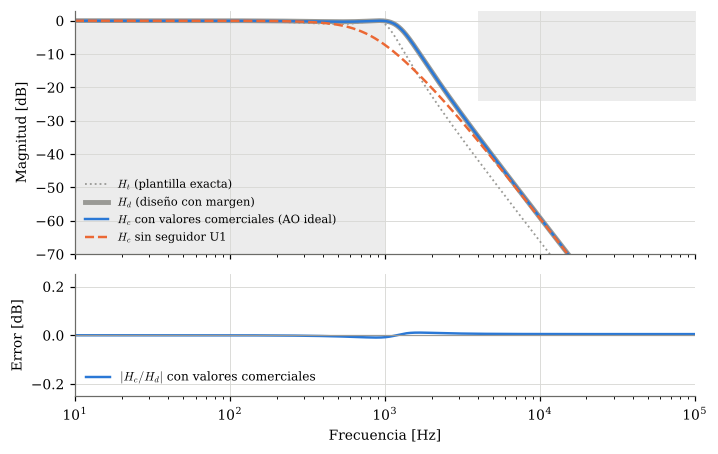

In [17]:
Hc_num = sp.lambdify(s, Hc.subs(sub_c), 'numpy')
sub_id = {Rs: 0, R0: 1 / (WR_T * C0_SEL), C0: C0_SEL, R1: R1_id, R2: R2_id, C1: C1_SEL, C2: C2_SEL}
Hc_id = sp.lambdify(s, Hc.subs(sub_id), 'numpy')
fz = np.geomspace(10, 1e5, 5000)
Hcv, Hdi, Hti, Hci = Hc_num(2j * np.pi * fz), Hd(fz), Ht(fz), Hc_id(2j * np.pi * fz)
err_sintesis = np.max(np.abs(Hci - Hdi))
print(f'Valores ideales (sin redondeo): max |Hc - Hd| = {err_sintesis:.2e}  -> la síntesis reproduce H_d exactamente')

H_nb_num = sp.lambdify(s, H_nb.subs(sub_c), 'numpy')(2j * np.pi * fz)
err_nb = 20 * np.log10(np.abs(H_nb_num / Hcv))
A1000 = -20 * np.log10(abs(Hc_num(2j * np.pi * FP_SPEC)))
A4000 = -20 * np.log10(abs(Hc_num(2j * np.pi * FS_SPEC)))
A1000_nb = -20 * np.log10(abs(H_nb_num[np.argmin(abs(fz - FP_SPEC))]))
print(f'Comercial: A_p,max = {Ap_c:.3f} dB, A(1 kHz) = {A1000:.3f} dB, A(4 kHz) = {A4000:.2f} dB')
print(f'Sin seguidor U1: error máximo de magnitud = {np.max(np.abs(err_nb)):.2f} dB (en {fz[np.argmax(np.abs(err_nb))]:.0f} Hz); '
      f'A(1 kHz) = {A1000_nb:.2f} dB')

fig, axs = plt.subplots(2, 1, figsize=(6.6, 4.2), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
axs[0].semilogx(fz, 20 * np.log10(np.abs(Hti)), color=GRIS, lw=1.2, ls=':', label='$H_t$ (plantilla exacta)')
axs[0].semilogx(fz, 20 * np.log10(np.abs(Hdi)), color=GRIS, lw=3.2, label='$H_d$ (diseño con margen)')
axs[0].semilogx(fz, 20 * np.log10(np.abs(Hcv)), color=AZUL, label='$H_c$ con valores comerciales (AO ideal)')
axs[0].semilogx(fz, 20 * np.log10(np.abs(H_nb_num)), color=NARANJA, ls='--', label='$H_c$ sin seguidor U1')
axs[0].fill_between([1, FP_SPEC], -90, -AP, color=GRIS, alpha=0.18, lw=0)
axs[0].fill_between([FS_SPEC, 1e6], -AS, 5, color=GRIS, alpha=0.18, lw=0)
axs[0].set(ylim=(-70, 3), ylabel='Magnitud [dB]'); axs[0].legend(fontsize=7.5, loc='lower left')
axs[1].semilogx(fz, 20 * np.log10(np.abs(Hcv / Hdi)), color=AZUL, label='$|H_c/H_d|$ con valores comerciales')
axs[1].axhline(0, color=GRIS, lw=0.8)
axs[1].set(xlim=(10, 1e5), ylim=(-0.25, 0.25), xlabel='Frecuencia [Hz]', ylabel='Error [dB]'); axs[1].legend(fontsize=8, loc='lower left')
fig.tight_layout(); guardar(fig, 'fig_Hc_vs_Ht'); plt.show()

### 6.4 Rendimiento esperado de la realización elegida
Monte Carlo analítico con los valores nominales elegidos (cada resistencia de un par en serie con su propia tolerancia del 1 %; capacitores con
±5 %, ±10 % y ±20 % porque su tolerancia no está confirmada). Se informa el porcentaje que cumple la plantilla y la distribución de $A_{p,\max}$.

In [18]:
comp_mc = {'Rs': RS_GEN, 'R0': COMP_SERIE['R0'], 'R1': COMP_SERIE['R1'], 'R2': COMP_SERIE['R2'],
           'C0': C0_SEL, 'C1': C1_SEL, 'C2': C2_SEL}
filas, dist = [], {}
for tolC in (0.05, 0.10, 0.20):
    Apm, A4 = monte_carlo(comp_mc, 0.01, tolC, M=40000)
    dist[tolC] = Apm
    filas.append({'tolerancia C': f'±{tolC*100:.0f} %', 'rendimiento [%]': 100 * np.mean((Apm <= AP) & (A4 >= AS)),
                  'A_p,max mediana [dB]': np.median(Apm), 'A_p,max p95 [dB]': np.percentile(Apm, 95),
                  'A(4 kHz) p0,5 [dB]': np.percentile(A4, 0.5)})
# referencia: misma topología sintetizando H_t (sin margen)
_, wr_t, w0_t, Q_t_ = cheby3(AP, FP_SPEC)
Apm_t, A4_t = monte_carlo(componentes_ideales(wr_t, w0_t, Q_t_), 0.01, 0.05, M=40000)
dist['sin margen'] = Apm_t
rend = pd.DataFrame(filas)
print(f'Referencia sin margen (H_t, C ±5 %): rendimiento {100*np.mean((Apm_t <= AP) & (A4_t >= AS)):.1f} %')
rend.round(3)

Referencia sin margen (H_t, C ±5 %): rendimiento 4.3 %


,tolerancia C,rendimiento [%],"A_p,max mediana [dB]","A_p,max p95 [dB]","A(4 kHz) p0,5 [dB]"
0,±5 %,100.000,0.387,0.546,33.626
1,±10 %,98.225,0.504,0.896,32.500
2,±20 %,64.230,0.819,1.723,30.034


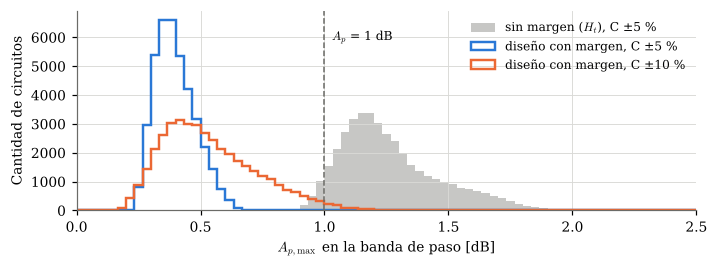

In [19]:
fig, ax = plt.subplots(figsize=(6.6, 2.5))
bins = np.linspace(0, 2.5, 76)
ax.hist(dist['sin margen'], bins=bins, color=GRIS, alpha=0.55, label='sin margen ($H_t$), C ±5 %')
ax.hist(dist[0.05], bins=bins, histtype='step', lw=1.6, color=AZUL, label='diseño con margen, C ±5 %')
ax.hist(dist[0.10], bins=bins, histtype='step', lw=1.6, color=NARANJA, label='diseño con margen, C ±10 %')
ax.axvline(AP, color='#6b6b67', lw=1.0, ls='--'); ax.text(AP + 0.03, ax.get_ylim()[1] * 0.85, '$A_p$ = 1 dB', fontsize=8)
ax.set(xlabel='$A_{p,\\max}$ en la banda de paso [dB]', ylabel='Cantidad de circuitos', xlim=(0, 2.5))
ax.legend(fontsize=8)
fig.tight_layout(); guardar(fig, 'fig_rendimiento'); plt.show()

## 7. Amplificador operacional
### 7.1 Datos de hoja técnica
El integrado disponible está marcado **TL072CP** (Texas Instruments; C: rango comercial 0–70 °C, P: encapsulado PDIP-8). Los datos siguen la hoja
TL07xx de TI (SLOS080) a ±15 V y 25 °C. La revisión actual de esa hoja especifica GBW típico de 5,25 MHz para este encapsulado; las revisiones
anteriores (y la versión de ST) indican 3–4 MHz. Para no depender de la revisión del silicio, los cálculos usan **3 MHz** (conservador).

In [20]:
AO = pd.DataFrame([
    ['GBW (típ.)', '5,25 MHz (rev. actual, PDIP); 3 MHz (rev. anteriores)', '0,7 MHz', 'cálculos con 3 MHz'],
    ['Slew rate', '13 V/µs típ., 8 V/µs mín.', '0,3 V/µs', 'ver amplitud y SR más abajo'],
    ['Alimentación', 'hasta ±18 V (máximo absoluto)', '3 a 32 V', 'se adopta ±12 V'],
    ['Modo común (±15 V)', '−12 a +15 V típ. (mín. ±11 V)', 'V− a V+ − 1,5 V', 'no incluye el riel negativo'],
    ['Excursión de salida (±15 V)', '±13,5 V típ.; mín. ±12 V (RL = 10 kΩ), ±10 V (RL ≥ 2 kΩ)', 'hasta V+ − 1,5 V', ''],
    ['Offset / polarización', '3 mV típ. (10 mV máx.); 65 pA típ. (200 pA máx.)', '2–7 mV; 20 nA típ. (250 nA máx.)', 'irrelevante en AC'],
    ['Consumo por AO', '1,4 mA típ.', '0,35 mA típ.', ''],
    ['Etapa de salida', 'clase AB', 'sin polarización clase AB', 'distorsión de cruce en LM358'],
], columns=['Parámetro', 'TL072CP (TI)', 'LM358', 'Comentario'])
AO

,Parámetro,TL072CP (TI),LM358,Comentario
0,GBW (típ.),"5,25 MHz (rev. actual, PDIP); 3 MHz (rev. ante...","0,7 MHz",cálculos con 3 MHz
1,Slew rate,"13 V/µs típ., 8 V/µs mín.","0,3 V/µs",ver amplitud y SR más abajo
2,Alimentación,hasta ±18 V (máximo absoluto),3 a 32 V,se adopta ±12 V
3,Modo común (±15 V),−12 a +15 V típ. (mín. ±11 V),"V− a V+ − 1,5 V",no incluye el riel negativo
4,Excursión de salida (±15 V),"±13,5 V típ.; mín. ±12 V (RL = 10 kΩ), ±10 V (...","hasta V+ − 1,5 V",
5,Offset / polarización,3 mV típ. (10 mV máx.); 65 pA típ. (200 pA máx.),2–7 mV; 20 nA típ. (250 nA máx.),irrelevante en AC
6,Consumo por AO,"1,4 mA típ.","0,35 mA típ.",
7,Etapa de salida,clase AB,sin polarización clase AB,distorsión de cruce en LM358


### 7.2 GBW finito sobre el circuito completo
Se repite el análisis nodal con $A(s) = \omega_t/s$ en ambos AO y se compara con el caso ideal en la banda de interés.

TL072CP, 5,25 MHz (rev. actual): desviación máx. de |H| hasta 4 kHz = 0.0087 dB; a 1 kHz = +0.0042 dB
TL072CP, 3 MHz (conservador): desviación máx. de |H| hasta 4 kHz = 0.0153 dB; a 1 kHz = +0.0074 dB
LM358, 0,7 MHz: desviación máx. de |H| hasta 4 kHz = 0.0654 dB; a 1 kHz = +0.0316 dB


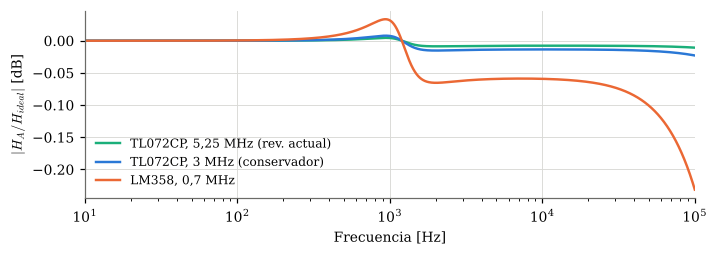

In [21]:
At = sp.Symbol('A_t')
sol_A = sp.solve(ecuaciones(A=At), V, dict=True)[0]
H_A = sp.simplify(sol_A[V6] / Vi)
fig, ax = plt.subplots(figsize=(6.6, 2.4))
desv = {}
for nombre, ft, col in [('TL072CP, 5,25 MHz (rev. actual)', 5.25e6, VERDE), ('TL072CP, 3 MHz (conservador)', 3e6, AZUL),
                        ('LM358, 0,7 MHz', 0.7e6, NARANJA)]:
    HAn = sp.lambdify(s, H_A.subs(sub_c).subs(At, 2 * np.pi * ft / s), 'numpy')(2j * np.pi * fz)
    d_ = 20 * np.log10(np.abs(HAn / Hcv))
    desv[nombre] = np.max(np.abs(d_[fz <= FS_SPEC]))
    ax.semilogx(fz, d_, color=col, label=nombre)
    print(f'{nombre}: desviación máx. de |H| hasta 4 kHz = {desv[nombre]:.4f} dB; a 1 kHz = {d_[np.argmin(abs(fz-1000))]:+.4f} dB')
ax.set(xlim=(10, 1e5), xlabel='Frecuencia [Hz]', ylabel='$|H_A/H_{ideal}|$ [dB]'); ax.legend(fontsize=8)
fig.tight_layout(); guardar(fig, 'fig_gbw_finito'); plt.show()

### 7.3 Amplitud máxima, slew rate, modo común y carga
- **Niveles internos:** $|V_k/V_i|$ en los nodos 2 (= 3), 4, 5 (= 6). El máximo fija la amplitud de entrada admisible.
- **Transitorio:** el sobrepico de la respuesta al escalón también debe caber en la excursión.
- **Slew rate requerido:** $\max_\omega\, \omega\,|V_k(j\omega)/V_i|\;V_{i,p}$ en cada salida de AO.
- **Excursión con ±12 V:** margen de 3 V a cada riel (mínimo de hoja de datos con RL = 10 kΩ a ±15 V), es decir ±9 V. El modo común de TL07x llega
  hasta ~3 V del riel negativo; con ±12 V se limita también a −9 V.

In [22]:
nv = res_alt[ALT]
gmax = {k_: np.abs(v).max() for k_, v in nv.items() if k_.startswith('V')}
fgmax = {k_: f[np.argmax(np.abs(v))] for k_, v in nv.items() if k_.startswith('V')}
for k_, g in gmax.items():
    print(f'|{k_}/Vi| máx = {g:.4f} ({20*np.log10(g):+.2f} dB) en {fgmax[k_]:.0f} Hz')
t_e, y_e = signal.step(signal.ZerosPolesGain(zt, pt, kt), T=np.linspace(0, 8e-3, 8001))
sobrepico = y_e.max()
VCC = 12.0; HEAD = 3.0
V_lim = VCC - HEAD
Vin_max = V_lim / max(max(gmax.values()), sobrepico)
print(f'\nSobrepico al escalón (H_d): {100*(sobrepico-1):.2f} %  ->  máximo transitorio = {sobrepico:.4f}·Vi')
print(f'Con ±{VCC:.0f} V y {HEAD:.0f} V de margen: |v| ≤ {V_lim:.1f} V en todo nodo  ->  V_i,p máx ≈ {Vin_max:.2f} V')

w = 2 * np.pi * f
SR_req = {}
for nodo, nombre in [('V2', 'U1'), ('V6', 'U2')]:
    SR_req[nombre] = np.max(w * np.abs(nv[nodo])) * Vin_max
    print(f'SR requerido en {nombre}: {SR_req[nombre]/1e6:.4f} V/µs (entrada senoidal de {Vin_max:.1f} V pico, peor frecuencia)')
SR_esc = np.max(np.diff(y_e) / np.diff(t_e)) * Vin_max
print(f'SR requerido ante escalón de {Vin_max:.1f} V: {SR_esc/1e6:.4f} V/µs')

Zmin_U1 = np.abs(nv['Zin_SK']).min()
Z_U2 = np.abs(1 / (2j * np.pi * f * COMP['C1']) + COMP['R1'] * COMP['R2'] / (COMP['R1'] + COMP['R2']))
print(f'\nCarga mínima de U1 (entrada del Sallen-Key): {Zmin_U1/1e3:.2f} kΩ  (≥ 2 kΩ: OK)')
print(f'Carga mínima de U2 a través de C1 (cota inferior, C1 + R1||R2, hasta 100 kHz): {Z_U2.min()/1e3:.2f} kΩ  (≥ 2 kΩ: OK)')

|V2/Vi| máx = 0.9999 (-0.00 dB) en 10 Hz
|V4/Vi| máx = 1.0190 (+0.16 dB) en 936 Hz
|V5/Vi| máx = 1.0000 (-0.00 dB) en 10 Hz
|V6/Vi| máx = 1.0000 (-0.00 dB) en 10 Hz

Sobrepico al escalón (H_d): 9.77 %  ->  máximo transitorio = 1.0977·Vi
Con ±12 V y 3 V de margen: |v| ≤ 9.0 V en todo nodo  ->  V_i,p máx ≈ 8.20 V
SR requerido en U1: 0.0398 V/µs (entrada senoidal de 8.2 V pico, peor frecuencia)
SR requerido en U2: 0.0533 V/µs (entrada senoidal de 8.2 V pico, peor frecuencia)
SR requerido ante escalón de 8.2 V: 0.0252 V/µs

Carga mínima de U1 (entrada del Sallen-Key): 6.23 kΩ  (≥ 2 kΩ: OK)
Carga mínima de U2 a través de C1 (cota inferior, C1 + R1||R2, hasta 100 kHz): 4.38 kΩ  (≥ 2 kΩ: OK)


**Conclusiones para el AO.**
- El GBW no es crítico: incluso el LM358 corre la respuesta apenas décimas de dB hasta 4 kHz. El slew rate necesario es del orden de
  centésimas de V/µs, muy por debajo del mínimo garantizado de TL07x (8 V/µs).
- Se usa el **TL072CP** disponible (U1 y U2 en un solo encapsulado; JFET de bajo ruido), con **TL081** como reemplazo por etapa. El LM358 se descarta
  por la distorsión de cruce de su etapa de salida al trabajar con señal alterna centrada en 0 V con fuente partida, por su mayor corriente de
  polarización y ruido, y por el límite de excursión a V+ − 1,5 V.
- **Alimentación ±12 V** desde la fuente partida, con desacople de 100 nF cerámico junto a cada pin de alimentación y 10 µF electrolítico por riel.
- **Amplitud de entrada:** para las mediciones se propone 1 V eficaz (≈ 1,41 V pico), muy por debajo del máximo calculado; puede subirse hasta ~5 V
  pico solo para medir la banda de rechazo con mejor relación señal/ruido.

## 8. Lista de materiales y exportación

In [23]:
bom = pd.DataFrame([
    ['U1, U2', 'TL072CP (DIP-8)', '—', 'AO doble JFET (TI)', 'Etapas 1 y 2; alternativa: 2 × TL081'],
    ['R0', txt_serie(COMP_SERIE['R0']), '1 %', 'Película metálica', f"Polo real; {ing(COMP['R0'],'Ω')} (ideal {ing(IDEAL['R0'],'Ω')}, con Rs = 50 Ω)"],
    ['C0', ing(COMP['C0'], 'F'), 'a confirmar', 'Film (poliéster/MKT) o C0G', 'Polo real'],
    ['R1', txt_serie(COMP_SERIE['R1']), '1 %', 'Película metálica', f"Sallen–Key, entrada; {ing(COMP['R1'],'Ω')} (ideal {ing(IDEAL['R1'],'Ω')})"],
    ['R2', txt_serie(COMP_SERIE['R2']), '1 %', 'Película metálica', f"Sallen–Key; {ing(COMP['R2'],'Ω')} (ideal {ing(IDEAL['R2'],'Ω')})"],
    ['C1', ing(COMP['C1'], 'F'), 'a confirmar', 'Film (poliéster/MKT)', 'Sallen–Key (realimentación)'],
    ['C2', ing(COMP['C2'], 'F'), 'a confirmar', 'Film (poliéster/MKT) o C0G', 'Sallen–Key (a masa)'],
    ['Cd1–Cd2', '100 nF', '—', 'Cerámico', 'Desacople, junto a pines 8 y 4'],
    ['Cd3–Cd4', '10 µF / 25 V', '—', 'Electrolítico', 'Desacople por riel'],
], columns=['Ref.', 'Valor', 'Tol.', 'Tipo', 'Función / observación'])
bom.to_csv(RES / 'bom.csv', index=False)
bom

,Ref.,Valor,Tol.,Tipo,Función / observación
0,"U1, U2",TL072CP (DIP-8),—,AO doble JFET (TI),Etapas 1 y 2; alternativa: 2 × TL081
1,R0,20 kΩ + 560 Ω,1 %,Película metálica,"Polo real; 20,56 kΩ (ideal 20,54 kΩ, con Rs = ..."
2,C0,10 nF,a confirmar,Film (poliéster/MKT) o C0G,Polo real
3,R1,"7,5 kΩ + 3,3 kΩ",1 %,Película metálica,"Sallen–Key, entrada; 10,8 kΩ (ideal 10,81 kΩ)"
4,R2,"6,8 kΩ + 560 Ω",1 %,Película metálica,"Sallen–Key; 7,36 kΩ (ideal 7,365 kΩ)"
5,C1,47 nF,a confirmar,Film (poliéster/MKT),Sallen–Key (realimentación)
6,C2,"4,7 nF",a confirmar,Film (poliéster/MKT) o C0G,Sallen–Key (a masa)
7,Cd1–Cd2,100 nF,—,Cerámico,"Desacople, junto a pines 8 y 4"
8,Cd3–Cd4,10 µF / 25 V,—,Electrolítico,Desacople por riel


In [24]:
def tabla_latex(df, columnas, alineacion):
    filas = [r'\begin{tabular}{@{}' + alineacion + r'@{}}', r'\toprule', ' & '.join(columnas) + r' \\', r'\midrule']
    for _, r in df.iterrows():
        filas.append(' & '.join(str(x) for x in r.values) + r' \\')
    filas += [r'\bottomrule', r'\end{tabular}']
    t = '\n'.join(filas)
    for a, b in [('%', r'\%'), ('Ω', r'$\Omega$'), ('µ', r'$\mu$'), ('±', r'$\pm$'), ('≥', r'$\ge$'), ('≤', r'$\le$'), ('≈', r'$\approx$'),
                 ('−', '$-$'), ('·', r'$\cdot$'), ('×', r'$\times$')]:
        t = t.replace(a, b)
    return t

(RES / 'tab_bom.tex').write_text(tabla_latex(bom, ['Ref.', 'Valor', 'Tol.', 'Tipo', 'Función / observación'],
                                             'p{1.2cm}p{3.0cm}p{1.8cm}p{2.9cm}p{5.4cm}'), encoding='utf-8')
(RES / 'tab_ao.tex').write_text(tabla_latex(AO, ['Parámetro', 'TL072CP (TI)', 'LM358', 'Comentario'],
                                            'p{3.0cm}p{5.4cm}p{3.4cm}p{3.0cm}'), encoding='utf-8')

# Comparación de diseños Sallen-Key (a Q de H_d)
lineas = [r'\begin{tabular}{@{}lccccccccc@{}}', r'\toprule',
          r'Diseño & $k$ & $C_1/C_2$ & $S^Q_{R_1}$ & $S^Q_{R_2}$ & $S^Q_{C_1}$ & $S^Q_{C_2}$ & $S^Q_{r_2}=-S^Q_{r_1}$ & $\Delta Q$ TL072 [\%] & $\Delta Q$ LM358 [\%] \\',
          r'\midrule']
for nombre, r in comp_dis.iterrows():
    lineas.append(f"{nombre} & {num(r.k, 3)} & {num(r['C1/C2'], 2)} & {num(r['S^Q_R_1'], 3)} & {num(r['S^Q_R_2'], 3)} & "
                  f"{num(r['S^Q_C_1'], 3)} & {num(r['S^Q_C_2'], 3)} & {num(r['S^Q_r_2'], 3)} & {num(r['dQ TL072 [%]'], 3)} & {num(r['dQ LM358 [%]'], 3)} \\\\")
lineas += [r'\bottomrule', r'\end{tabular}']
(RES / 'tab_disenos_sk.tex').write_text('\n'.join(lineas), encoding='utf-8')

# Estudio de margen
lineas = [r'\begin{tabular}{@{}ccccccc@{}}', r'\toprule',
          r'$A_{p,d}$ [dB] & $f_{p,d}$ [Hz] & $Q$ & Rend. C $\pm$5\,\% [\%] & Rend. C $\pm$10\,\% [\%] & $A_{p,\max}$ p95, C $\pm$10\,\% [dB] & $A(\qty{4}{\kilo\hertz})$ [dB] \\',
          r'\midrule']
for _, r in margen.iterrows():
    neg = r'\textbf' if (r['A_p,d [dB]'] == AP_D and r['f_p,d [Hz]'] == FP_D) else ''
    celdas = [num(r['A_p,d [dB]'], 2), f"{r['f_p,d [Hz]']:.0f}", num(r['Q'], 3), num(r['rend. C±5% [%]'], 1), num(r['rend. C±10% [%]'], 1),
              num(r['A_p p95 C±10% [dB]'], 2), num(r['A(4 kHz) nominal [dB]'], 1)]
    lineas.append(' & '.join((neg + '{' + c + '}') if neg else c for c in celdas) + r' \\')
lineas += [r'\bottomrule', r'\end{tabular}']
(RES / 'tab_margen.tex').write_text('\n'.join(lineas), encoding='utf-8')

# Elección de capacitores
lineas = [r'\begin{tabular}{@{}ccccccc@{}}', r'\toprule',
          r'$C_1$ & $C_2$ & $n$ & $R_{\mathrm{may}}$ ideal & $R_{\mathrm{men}}$ ideal & $S^Q_{R_1}$ & $\Delta f_0$ con E24 simple [\%] \\', r'\midrule']
for _, r in cand.iterrows():
    neg = np.isclose(r.C1, C1_SEL, rtol=1e-6, atol=0) and np.isclose(r.C2, C2_SEL, rtol=1e-6, atol=0)
    celdas = [ing(r.C1, 'F'), ing(r.C2, 'F'), num(r.n, 2), ing(r['R_may ideal'], 'Ω'), ing(r['R_men ideal'], 'Ω'), num(r['S^Q_R1'], 3), num(r['df0 E24 %'], 2)]
    lineas.append(' & '.join(r'\textbf{' + c + '}' if neg else c for c in celdas) + r' \\')
lineas += [r'\bottomrule', r'\end{tabular}']
t = '\n'.join(lineas)
for a, b in [('Ω', r'$\Omega$'), ('µ', r'$\mu$')]:
    t = t.replace(a, b)
(RES / 'tab_capacitores.tex').write_text(t, encoding='utf-8')

# Resistencias: ideal, E24 simple y realización
lineas = [r'\begin{tabular}{@{}lccccc@{}}', r'\toprule',
          r'Ref. & Ideal & E24 simple & Error [\%] & Realización (1\,\%) & Error [\%] \\', r'\midrule']
for _, r in tab_r.iterrows():
    lineas.append(f"${r.ref[0]}_{r.ref[1]}$ & {r.ideal} & {r['E24 simple']} & {num(r['error E24 simple %'], 2)} & {r['realización']} & {num(r['error %'], 3)} \\\\")
lineas += [r'\bottomrule', r'\end{tabular}']
t = '\n'.join(lineas).replace('Ω', r'$\Omega$')
(RES / 'tab_resistencias.tex').write_text(t, encoding='utf-8')

# Recálculo con comerciales
lineas = [r'\begin{tabular}{@{}lccc@{}}', r'\toprule', r'Parámetro & Objetivo ($H_d$) & Comercial & Error [\%] \\', r'\midrule']
for nombre, (_, r) in zip([r'$f_r$ [Hz]', r'$f_0$ [Hz]', r'$Q$'], recalc.iterrows()):
    nd = 4 if nombre == r'$Q$' else 2
    lineas.append(f"{nombre} & {num(r['objetivo (H_d)'], nd)} & {num(r['comercial'], nd)} & {num(r['error %'], 3)} \\\\")
lineas += [r'\midrule',
           f'$A_{{p,\\max}}$ en $f \\le \\qty{{1}}{{\\kilo\\hertz}}$ [dB] (plantilla: $\\le 1$) & {num(AP_D, 3)} & {num(Ap_c, 3)} & --- \\\\',
           f'$A(\\qty{{4}}{{\\kilo\\hertz}})$ [dB] (plantilla: $\\ge 24$) & {num(-20*np.log10(abs(Hd([FS_SPEC])[0])), 2)} & {num(A4000, 2)} & --- \\\\',
           r'\bottomrule', r'\end{tabular}']
(RES / 'tab_recalculo.tex').write_text('\n'.join(lineas), encoding='utf-8')

# Rendimiento de la realización elegida
lineas = [r'\begin{tabular}{@{}lcccc@{}}', r'\toprule',
          r'Tolerancia de $C$ & Rendimiento [\%] & $A_{p,\max}$ mediana [dB] & $A_{p,\max}$ p95 [dB] & $A(\qty{4}{\kilo\hertz})$ p0,5 [dB] \\', r'\midrule']
for _, r in rend.iterrows():
    tol_txt = r['tolerancia C'].replace('±', '$\\pm$').replace('%', '\\%')
    lineas.append(f"{tol_txt} & {num(r['rendimiento [%]'], 1)} & {num(r['A_p,max mediana [dB]'], 3)} & "
                  f"{num(r['A_p,max p95 [dB]'], 3)} & {num(r['A(4 kHz) p0,5 [dB]'], 1)} \\\\")
lineas += [r'\bottomrule', r'\end{tabular}']
(RES / 'tab_rendimiento.tex').write_text('\n'.join(lineas), encoding='utf-8')

# Parámetros para notebook 03 y LTspice
json.dump({'componentes': COMP, 'resistencias_en_serie': COMP_SERIE, 'ideales': IDEAL,
           'plantilla': {'Ap': AP, 'As': AS, 'fp': FP_SPEC, 'fs': FS_SPEC},
           'diseno': {'Ap_d': AP_D, 'fp_d': FP_D, 'N': int(N), 'fr': FR_T, 'f0': F0_T, 'Q': Q_T},
           'comercial': {'fr': wr_v / (2 * np.pi), 'f0': w0_v / (2 * np.pi), 'Q': Q_v},
           'alimentacion_V': VCC, 'Vin_max_pico_V': Vin_max, 'AO': 'TL072CP (Texas Instruments)'},
          open(RES / 'componentes.json', 'w'), indent=2, ensure_ascii=False)

# Valores numéricos para el informe (macros LaTeX; se usan con \num{} / \qty{}{})
rend_ref = 100 * np.mean((Apm_t <= AP) & (A4_t >= AS))
VAL = {
    'ApD': AP_D, 'FpD': int(FP_D), 'FrD': round(FR_T, 2), 'FoD': round(F0_T, 2), 'QD': round(Q_T, 4), 'CuatroQcuad': round(4 * Q_T**2, 2),
    'FrC': round(wr_v / (2 * np.pi), 2), 'FoC': round(w0_v / (2 * np.pi), 2), 'QC': round(Q_v, 4),
    'ApC': round(Ap_c, 3), 'AcuatroC': round(A4000, 2), 'AcuatroD': round(-20 * np.log10(abs(Hd([FS_SPEC])[0])), 2),
    'ApEsimple': round(Ap_s, 3), 'SQRuno': round(SQR1, 3), 'ErrSintesis': f'{err_sintesis:.0e}',
    'RendSinMargen': round(rend_ref, 1), 'RendCinco': round(rend.iloc[0]['rendimiento [%]'], 1),
    'RendDiez': round(rend.iloc[1]['rendimiento [%]'], 1), 'RendVeinte': round(rend.iloc[2]['rendimiento [%]'], 1),
    'ErrSinBuffer': round(float(np.max(np.abs(err_nb))), 1), 'AmilSinBuffer': round(A1000_nb, 1),
    'NodoCuatroMax': round(gmax['V4'], 3), 'NodoCuatroF': int(round(float(fgmax['V4']))),
    'NodoCuatroMaxAlt': round(float(np.abs(res_alt['R1 menor (entrada)']['V4']).max()), 3),
    'ZminUuno': round(Zmin_U1 / 1e3, 1), 'ZminUunoAlt': round(float(np.abs(res_alt['R1 menor (entrada)']['Zin_SK']).min()) / 1e3, 1),
    'ZminUdos': round(float(Z_U2.min()) / 1e3, 1), 'Sobrepico': round(100 * (sobrepico - 1), 1), 'VinMax': round(Vin_max, 1),
    'SRUuno': round(SR_req['U1'] / 1e6, 3), 'SRUdos': round(SR_req['U2'] / 1e6, 3), 'SREscalon': round(SR_esc / 1e6, 3),
    'GBWdevTL': round(desv['TL072CP, 3 MHz (conservador)'], 3), 'GBWdevLM': round(desv['LM358, 0,7 MHz'], 2),
    'RnMay': round(Rn_may, 5), 'RnMen': round(Rn_men, 5), 'Kf': round(kf, 2), 'Kz': int(round(kz)),
    'RunoId': round(R1_id / 1e3, 3), 'RdosId': round(R2_id / 1e3, 3), 'RceroId': round(R0_id / 1e3, 3),
    'RceroMasRs': round((R0_id + RS_GEN) / 1e3, 3),
}
macros = ['% Generado automáticamente por notebooks/02_Sintesis_Simbolica_y_Componentes.ipynb — no editar a mano']
macros += [f'\\newcommand{{\\v{k_}}}{{{v}}}' for k_, v in VAL.items()]
(RES / 'valores_nb02.tex').write_text('\n'.join(macros) + '\n', encoding='utf-8')

expr = {'Hc': sp.latex(Hc), 'T1': sp.latex(T1c), 'T2': sp.latex(T2c), 'wr': sp.latex(wr_c), 'w0': sp.latex(w0_c),
        'Q': sp.latex(Q_c), 'Hnb_diff': sp.latex(dif)}
json.dump(expr, open(RES / 'expresiones_nb02.json', 'w'), indent=2)
print('\n'.join(macros))
print('Exportado:', sorted(x.name for x in RES.iterdir()))

% Generado automáticamente por notebooks/02_Sintesis_Simbolica_y_Componentes.ipynb — no editar a mano
\newcommand{\vApD}{0.3}
\newcommand{\vFpD}{1060}
\newcommand{\vFrD}{773.03}
\newcommand{\vFoD}{1200.12}
\newcommand{\vQD}{1.5525}
\newcommand{\vCuatroQcuad}{9.64}
\newcommand{\vFrC}{772.22}
\newcommand{\vFoC}{1201.08}
\newcommand{\vQC}{1.5525}
\newcommand{\vApC}{0.305}
\newcommand{\vAcuatroC}{34.72}
\newcommand{\vAcuatroD}{34.72}
\newcommand{\vApEsimple}{0.411}
\newcommand{\vSQRuno}{-0.095}
\newcommand{\vErrSintesis}{3e-15}
\newcommand{\vRendSinMargen}{4.4}
\newcommand{\vRendCinco}{100.0}
\newcommand{\vRendDiez}{98.2}
\newcommand{\vRendVeinte}{64.2}
\newcommand{\vErrSinBuffer}{8.7}
\newcommand{\vAmilSinBuffer}{7.2}
\newcommand{\vNodoCuatroMax}{1.019}
\newcommand{\vNodoCuatroF}{936}
\newcommand{\vNodoCuatroMaxAlt}{1.042}
\newcommand{\vZminUuno}{6.2}
\newcommand{\vZminUunoAlt}{4.4}
\newcommand{\vZminUdos}{4.4}
\newcommand{\vSobrepico}{9.8}
\newcommand{\vVinMax}{8.2}
\newcommand{\vSRUuno}